# 08 · Tune and break

Goal: find where the detector fails and which parameter moves the failure.

| Parameter | Block | Trade-off |
|---|---|---|
| `mask_low`, `mask_high` | mask | dim or washed-out paint vs noise |
| `line_level`, `min_mass` | scan | faint lines vs specks |
| `near_rows`, `far_rows` | scan, camera | resolution and visibility vs lookahead |
| `tolerance` | centre | distractor rejection vs track-width error |

In [1]:
%load_ext autoreload
%autoreload 2
import math
import numpy as np
import matplotlib.pyplot as plt
from helpers import SyntheticTrack, synthetic_drive, show, table, use_style
use_style()

from lanedet.camera import Camera
from lanedet.detector import LaneDetector
from lanedet.mask import to_float, yellow_mask
from lanedet.scan import band_profile

base = SyntheticTrack()
CAM = Camera(base.width, base.height, base.focal, base.cam_height, base.v_horizon)

def evaluate(n=120, transform=None, **det_kwargs):
    det = LaneDetector(CAM, **det_kwargs)
    zn = float(CAM.distance(det.band_row(det.near_rows)))
    zf = float(CAM.distance(det.band_row(det.far_rows)))
    el, eh, seen, pairs = [], [], 0, 0
    for frame, tr in synthetic_drive(n, noise=8):
        d = det(frame if transform is None else transform(frame))
        xn, xf = tr.centre_x(zn), tr.centre_x(zf)
        el.append(d.e_lat - np.clip(xn / tr.half_width, -1, 1))
        eh.append(d.e_heading - math.atan2(xf - xn, zf - zn))
        seen += d.near.case != "none" and d.far.case != "none"
        pairs += d.near.case == "pair" and d.far.case == "pair"
    return {"e_lat RMSE": float(np.sqrt(np.mean(np.square(el)))),
            "e_heading RMSE (°)": float(np.degrees(np.sqrt(np.mean(np.square(eh))))),
            "lines seen": seen / n,
            "both paired": pairs / n}

## Stress conditions

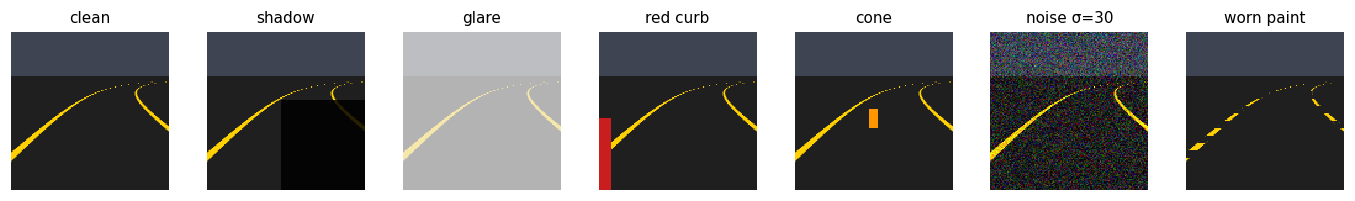

condition,e_lat RMSE,e_heading RMSE (°),lines seen,both paired
clean,0.010,0.571,1.000,0.875
shadow,0.012,2.144,1.000,0.000
glare,0.008,29.186,0.000,0.000
red curb,0.023,1.087,1.000,0.875
cone,0.010,0.571,1.000,0.875
noise σ=30,0.010,0.963,1.000,0.875
worn paint,0.019,1.860,1.000,0.875


In [2]:
rng = np.random.default_rng(0)

def shadow(f):  # tree shadow over the right half
    f = f.astype(np.float32)
    f[55:, 60:] *= 0.15
    return f.astype(np.uint8)

def glare(f):  # washed-out image
    return np.clip(f.astype(np.float32) * 0.3 + 170, 0, 255).astype(np.uint8)

def red_curb(f):
    f = f.copy()
    f[70:, :10] = (200, 30, 30)
    return f

def cone(f):
    f = f.copy()
    f[62:78, 60:67] = (255, 150, 0)
    return f

def heavy_noise(f):
    return np.clip(f + rng.normal(0, 30, f.shape), 0, 255).astype(np.uint8)

def worn_paint(f):  # paint missing in every other block of 6 rows
    f = f.copy()
    y = np.minimum(f[..., 0], f[..., 1]).astype(int) - f[..., 2]
    for r0 in range(0, f.shape[0], 12):
        f[r0:r0 + 6][y[r0:r0 + 6] > 60] = (31, 31, 31)
    return f

STRESS = {"clean": None, "shadow": shadow, "glare": glare, "red curb": red_curb,
          "cone": cone, "noise σ=30": heavy_noise, "worn paint": worn_paint}
sample = SyntheticTrack(offset=0.04, curvature=0.5).render(seed=1)
show([sample if t is None else t(sample) for t in STRESS.values()], list(STRESS), cols=7, size=1.8)
default = {k: evaluate(transform=t) for k, t in STRESS.items()}
table([{"condition": k} | r for k, r in default.items()])

Two failures:

- **glare** — the detector goes blind: no lines seen, the heading freezes.
- **shadow** — the shadowed line is lost, pairs drop to zero, the detector runs on single lines and the heading error grows.

Red curb, cone and noise are already handled by the colour score (02), pairing (05) and the mass threshold (03).

## Diagnosis

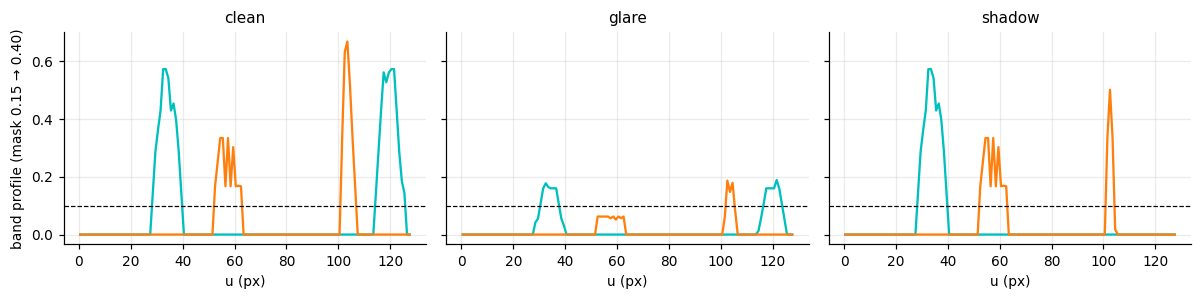

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(11, 2.8), sharey=True)
for a, (name, t) in zip(ax, (("clean", None), ("glare", glare), ("shadow", shadow))):
    m = yellow_mask(to_float(sample if t is None else t(sample)))
    for band, colour in (((68, 75), "c"), ((52, 58), "tab:orange")):
        a.plot(np.arange(128) + 0.5, band_profile(m, band), color=colour)
    a.axhline(0.1, color="k", ls="--", lw=0.8)
    a.set(title=name, xlabel="u (px)")
ax[0].set_ylabel("band profile (mask 0.15 → 0.40)")
plt.tight_layout()
plt.show()

Both conditions dim the paint's yellowness to ~0.2 — close to `mask_low = 0.15`, so the mask barely responds and the lines sink under the level. Lowering `mask_low` recovers dim paint; lowering `mask_high` makes it saturate sooner. Both also let more noise through. Sweep the ramp under all three:

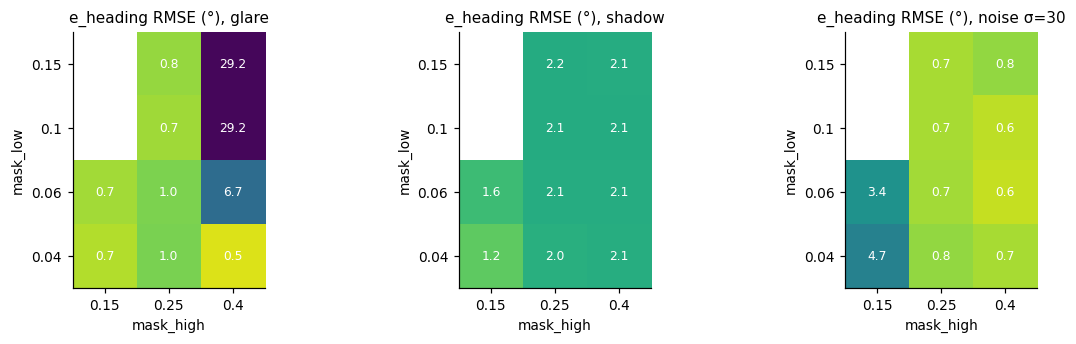

In [4]:
lows, highs = [0.04, 0.06, 0.10, 0.15], [0.15, 0.25, 0.40]
conditions = {"glare": glare, "shadow": shadow, "noise σ=30": heavy_noise}
grids = {name: np.full((len(lows), len(highs)), np.nan) for name in conditions}
for name, t in conditions.items():
    for i, lo in enumerate(lows):
        for j, hi in enumerate(highs):
            if hi > lo + 0.05:
                grids[name][i, j] = evaluate(n=60, transform=t, mask_low=lo, mask_high=hi)["e_heading RMSE (°)"]

fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
for a, (name, g) in zip(ax, grids.items()):
    a.imshow(np.log10(g), cmap="viridis_r", origin="lower", vmin=-0.4, vmax=1.5)
    a.set_xticks(range(len(highs)), highs)
    a.set_yticks(range(len(lows)), lows)
    a.set(xlabel="mask_high", ylabel="mask_low", title=f"e_heading RMSE (°), {name}")
    a.grid(False)
    for (i, j), val in np.ndenumerate(g):
        if not np.isnan(val):
            a.text(j, i, f"{val:.1f}", ha="center", va="center", fontsize=8, color="w")
plt.tight_layout()
plt.show()

- Glare and shadow want a low ramp.
- Noise punishes a ramp that is both low and short (`low ≤ 0.06, high = 0.15`): specks saturate to 1, gain mass, and survive the mass threshold.
- `mask_low = 0.05, mask_high = 0.25` is good in all three.

## Band distance

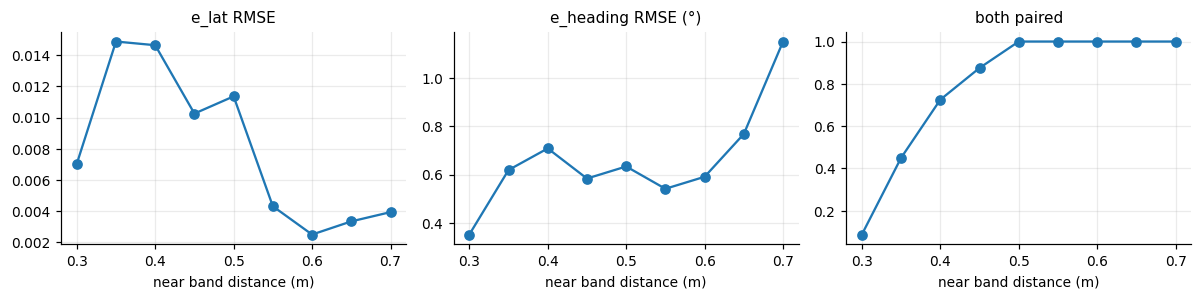

In [5]:
zs = np.linspace(0.30, 0.70, 9)
res = []
for z in zs:
    v = CAM.v_horizon + CAM.focal * CAM.cam_height / z
    res.append(evaluate(n=80, near_rows=(int(round(v - 3.5)), int(round(v + 3.5)))))

fig, ax = plt.subplots(1, 3, figsize=(11, 2.8))
for a, key in zip(ax, ("e_lat RMSE", "e_heading RMSE (°)", "both paired")):
    a.plot(zs, [r[key] for r in res], "o-")
    a.set(xlabel="near band distance (m)", title=key)
plt.tight_layout()
plt.show()

Closer bands have more pixels per metre but lose a line sooner, and shorten the baseline to the far band, so the heading degrades. 0.45 m keeps the most frames paired.

Caveat: on the synthetic track the width is exact, so single-line estimates are nearly perfect. On a real track the width varies; prefer settings that keep both lines paired.

## Configuration

In [6]:
CONFIG = dict(mask_low=0.05, mask_high=0.25, line_level=0.1, min_mass=1.0,
              near_rows=(68, 75), far_rows=(52, 58), tolerance=0.35)

tuned = {k: evaluate(transform=t, **CONFIG) for k, t in STRESS.items()}
table([{"condition": k,
        "heading° default": default[k]["e_heading RMSE (°)"], "heading° tuned": tuned[k]["e_heading RMSE (°)"],
        "paired default": default[k]["both paired"], "paired tuned": tuned[k]["both paired"]} for k in STRESS])

condition,heading° default,heading° tuned,paired default,paired tuned
clean,0.571,0.517,0.875,0.875
shadow,2.144,2.030,0.000,0.617
glare,29.186,1.063,0.000,0.825
red curb,1.087,1.049,0.875,0.875
cone,0.571,0.517,0.875,0.875
noise σ=30,0.963,0.794,0.875,0.883
worn paint,1.860,1.841,0.875,0.875


Glare is fixed and shadow keeps both lines paired, but shadow still costs ~2° of heading. Cause: the shadow edge (row 55) cuts through the far band (rows 52–58). Bright rows outweigh dim rows in the band average, so the centroid is pulled toward where the slanted line sits in the upper rows — a ~1.5 cm bias at 0.85 m. No threshold fixes that; it is a limit of averaging a band. Options: find lines per row and fit a line through them, or normalise the colour score by local brightness.

## Check

In [7]:
assert all(r["lines seen"] == 1.0 for r in tuned.values())
assert all(r["e_heading RMSE (°)"] < 2.5 for r in tuned.values())
assert tuned["glare"]["e_heading RMSE (°)"] < 2.0 < default["glare"]["e_heading RMSE (°)"]
assert tuned["shadow"]["both paired"] > 0.5 > default["shadow"]["both paired"]

## Next steps

- Make `CONFIG` the default of `LaneDetector`.
- Per-row line finding, or a brightness-normalised score, to remove the shadow bias.
- Calibrate `Camera` to the Isaac sim camera; its intrinsics and mounting are known exactly.
- Port the blocks to PyTorch, batched over environments, to feed the RL observation.